# Cây quyết định chia không gian đặc trưng thành các hình chữ nhật (mục 6.1.1)

Dữ liệu Iris, hai đặc trưng chiều dài và chiều rộng cánh hoa, cây độ sâu 3

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier, plot_tree

IMAGES = Path('.')   # thư mục images/ (notebook chạy trong images/)

iris = load_iris()
X = iris.data[:, 2:4]                       # chiều dài, chiều rộng cánh hoa (cm)
y = iris.target
names = ['petal length', 'petal width']
tree = DecisionTreeClassifier(max_depth=3, random_state=0).fit(X, y)
x_range, y_range = (0.8, 7.2), (0, 2.7)

def draw_splits(ax, node, x_min, x_max, y_min, y_max):
    """Vẽ đệ quy đường chia của mỗi nút trong vùng hình chữ nhật mà nút đó phụ trách."""
    left, right = tree.tree_.children_left[node], tree.tree_.children_right[node]
    if left < 0:                            # nút lá: không chia nữa
        return
    t = tree.tree_.threshold[node]
    if tree.tree_.feature[node] == 0:       # chia theo chiều dài: đường thẳng đứng
        ax.plot([t, t], [y_min, y_max], color='k', lw=1.3)
        draw_splits(ax, left, x_min, t, y_min, y_max)
        draw_splits(ax, right, t, x_max, y_min, y_max)
    else:                                   # chia theo chiều rộng: đường nằm ngang
        ax.plot([x_min, x_max], [t, t], color='k', lw=1.3)
        draw_splits(ax, left, x_min, x_max, y_min, t)
        draw_splits(ax, right, x_min, x_max, t, y_max)

Vẽ hình và lưu ảnh.

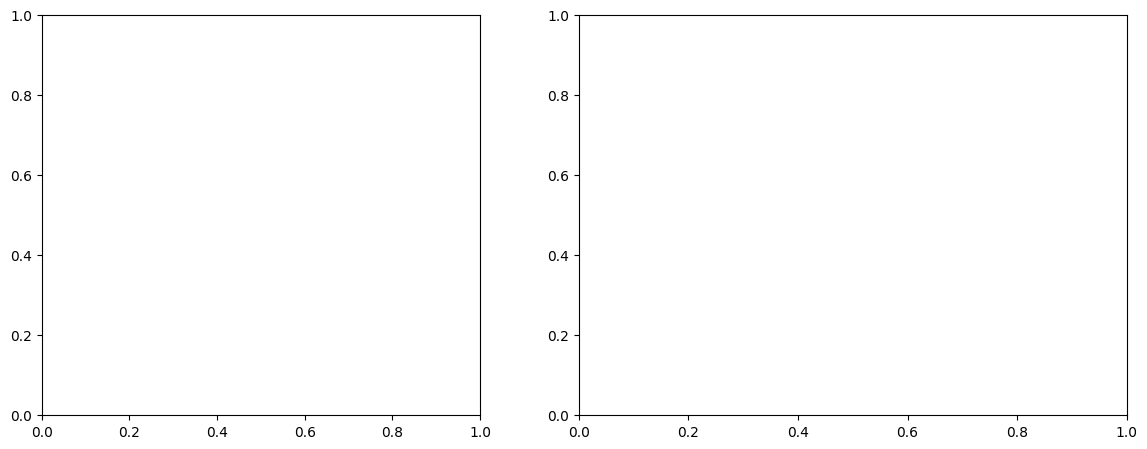

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={'width_ratios': [1, 1.25]})

(a) các vùng quyết định

In [3]:
xx, yy = np.meshgrid(np.linspace(*x_range, 400), np.linspace(*y_range, 400))
zz = tree.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
colors = ['#1F77B4', '#2CA02C', '#D62728']
axes[0].contourf(xx, yy, zz, levels=[-0.5, 0.5, 1.5, 2.5], colors=colors, alpha=0.15)
for k, name in enumerate(iris.target_names):
    axes[0].scatter(X[y == k, 0], X[y == k, 1], s=18, color=colors[k], edgecolors='k', linewidths=0.3, label=name)
draw_splits(axes[0], 0, *x_range, *y_range)
axes[0].set_xlim(*x_range); axes[0].set_ylim(*y_range)
axes[0].set_xlabel('Chiều dài cánh hoa (cm)'); axes[0].set_ylabel('Chiều rộng cánh hoa (cm)')
axes[0].set_title('(a) Mỗi nút lá ứng với một vùng hình chữ nhật')
axes[0].legend(loc='upper left', fontsize=9)

(b) cây tương ứng

In [4]:
plot_tree(tree, feature_names=names, class_names=list(iris.target_names), filled=True,
          rounded=True, impurity=False, fontsize=8, ax=axes[1])
axes[1].set_title('(b) Cây quyết định độ sâu 3')
fig.tight_layout()
fig.savefig(IMAGES / 'tree_regions.png', dpi=150)